Total images: 433
Width range: 225 to 600 px (Mean: 425.1)
Height range: 141 to 531 px (Mean: 292.1)
Data type: uint8 | Intensity range: [0, 255]


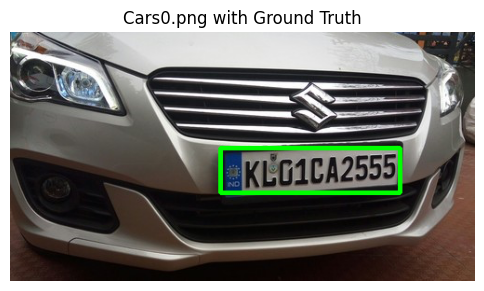

In [ ]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_dir = "dataset/ds/img"
ann_dir = "dataset/ds/ann"

img_files = sorted(os.listdir(img_dir))
sizes = []

for f in img_files:
    img = cv2.imread(os.path.join(img_dir, f))
    if img is not None:
        h, w, _ = img.shape
        sizes.append((w, h))

widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]
sample_img = cv2.imread(os.path.join(img_dir, img_files[0]))

print(f"Total images: {len(sizes)}")
print(f"Width range: {min(widths)} to {max(widths)} px (Mean: {np.mean(widths):.1f})")
print(f"Height range: {min(heights)} to {max(heights)} px (Mean: {np.mean(heights):.1f})")
print(f"Data type: {sample_img.dtype} | Intensity range: [{sample_img.min()}, {sample_img.max()}]")

sample_name = img_files[0]
with open(os.path.join(ann_dir, sample_name + ".json"), "r") as jf:
    ann_data = json.load(jf)

img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
for obj in ann_data["objects"]:
    pts = obj["points"]["exterior"]
    x1, y1 = int(pts[0][0]), int(pts[0][1])
    x2, y2 = int(pts[1][0]), int(pts[1][1])
    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)

plt.figure(figsize=(6, 4))
plt.imshow(img_rgb)
plt.title(f"{sample_name} with Ground Truth")
plt.axis("off")
plt.show()

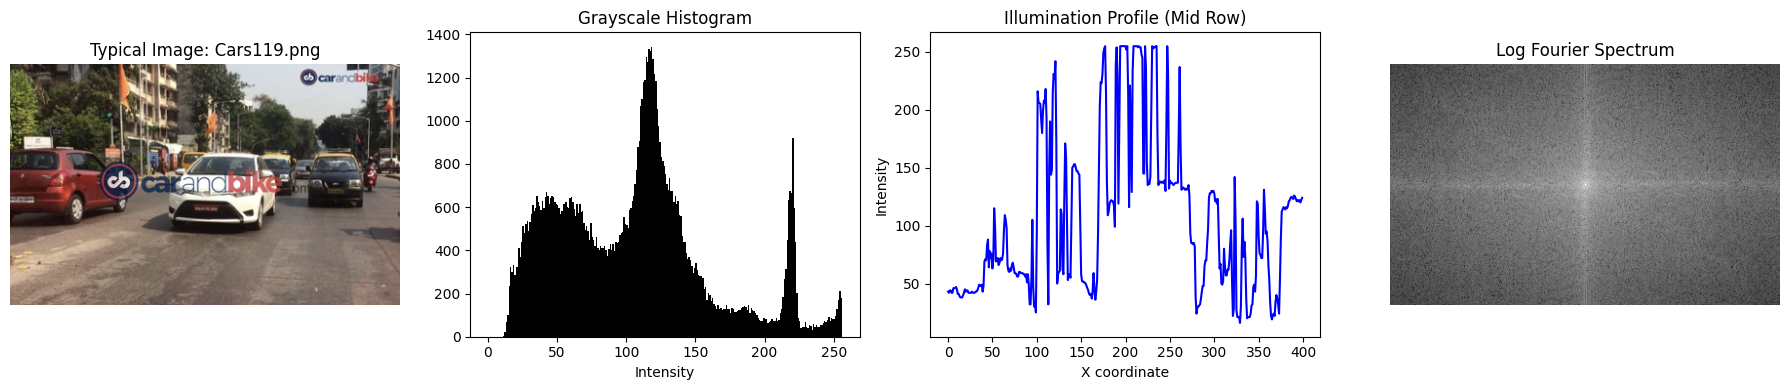

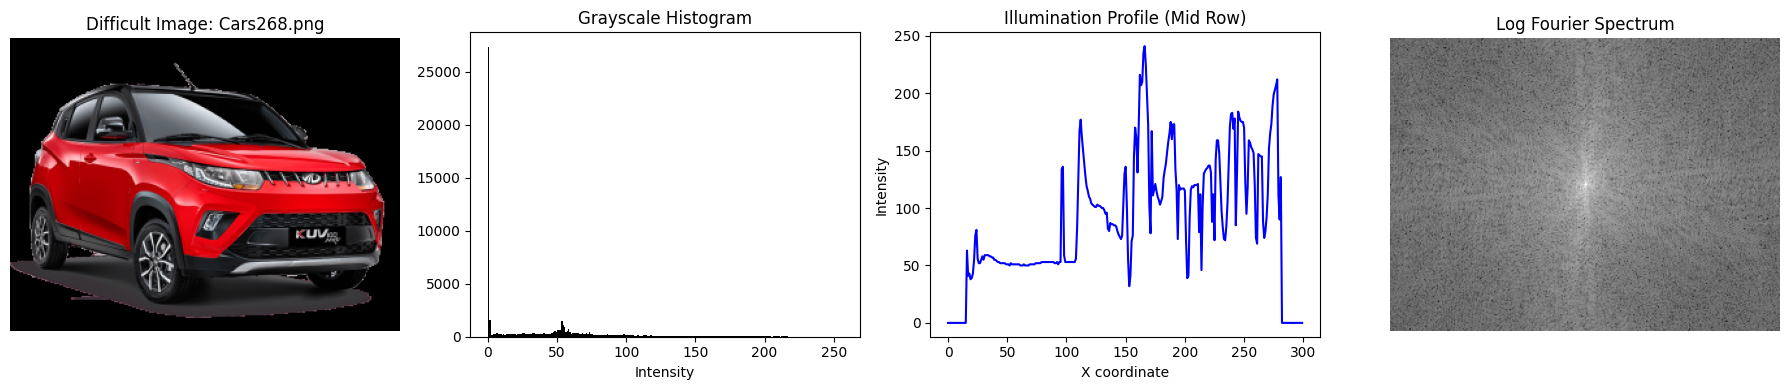

In [ ]:

means = []
for f in img_files:
    g = cv2.imread(os.path.join(img_dir, f), cv2.IMREAD_GRAYSCALE)
    means.append((np.mean(g), f))

means.sort()
difficult_file = means[0][1]                  # أغمق صورة في الداتا
typical_file = means[len(means) // 2][1]      # صورة متوسطة الإضاءة

def plot_full_analysis(filename, label):
    path = os.path.join(img_dir, filename)
    bgr = cv2.imread(path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    # حساب Centred Log-Magnitude Fourier Spectrum
    f = np.fft.fft2(gray)
    fshift = np.fft.fftshift(f)
    spectrum = np.log(1 + np.abs(fshift))

    # أخذ مقطع أفقي في منتصف الصورة لقياس تغير الإضاءة (Illumination profile)
    mid_row = gray[gray.shape[0] // 2, :]

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    axes[0].imshow(rgb)
    axes[0].set_title(f"{label}: {filename}")
    axes[0].axis("off")

    axes[1].hist(gray.ravel(), bins=256, range=[0, 256], color='black')
    axes[1].set_title("Grayscale Histogram")
    axes[1].set_xlabel("Intensity")

    axes[2].plot(mid_row, color='blue')
    axes[2].set_title("Illumination Profile (Mid Row)")
    axes[2].set_xlabel("X coordinate")
    axes[2].set_ylabel("Intensity")

    axes[3].imshow(spectrum, cmap='gray')
    axes[3].set_title("Log Fourier Spectrum")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()

plot_full_analysis(typical_file, "Typical Image")
plot_full_analysis(difficult_file, "Difficult Image")

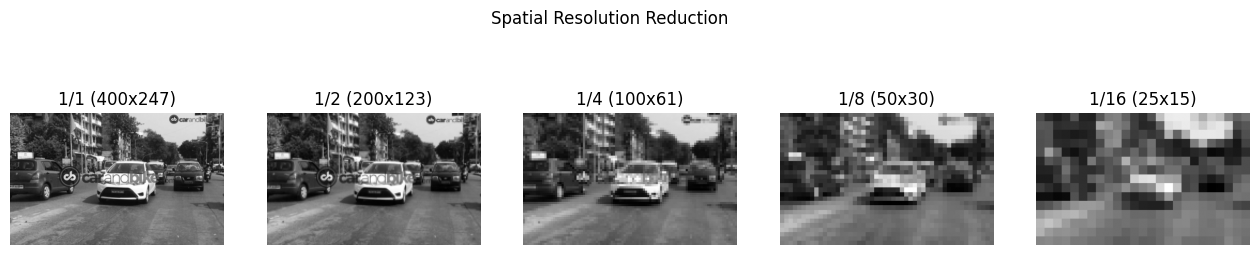

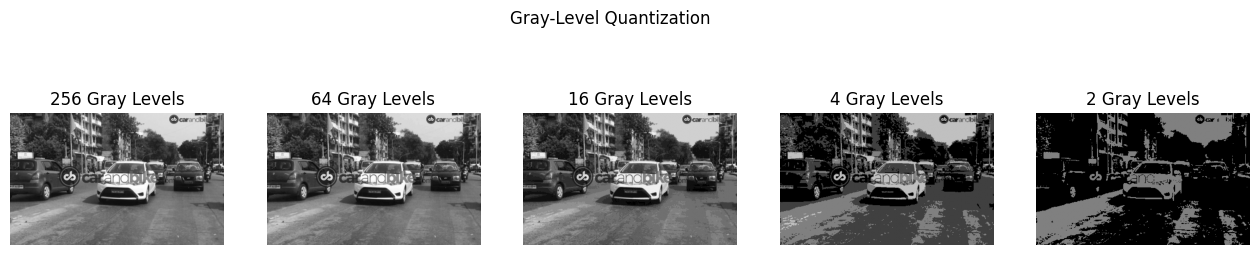

In [ ]:
img_gray = cv2.imread(os.path.join(img_dir, typical_file), cv2.IMREAD_GRAYSCALE)
h, w = img_gray.shape

# 1. تقليل Spatial Resolution
scales = [1, 2, 4, 8, 16]
fig, axes = plt.subplots(1, len(scales), figsize=(16, 3.5))
for i, s in enumerate(scales):
    small = cv2.resize(img_gray, (w // s, h // s), interpolation=cv2.INTER_AREA)
    back = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
    axes[i].imshow(back, cmap='gray')
    axes[i].set_title(f"1/{s} ({w//s}x{h//s})")
    axes[i].axis("off")
plt.suptitle("Spatial Resolution Reduction")
plt.show()

# 2. تقليل Gray Levels
levels = [256, 64, 16, 4, 2]
fig, axes = plt.subplots(1, len(levels), figsize=(16, 3.5))
for i, L in enumerate(levels):
    step = 256 // L
    quantized = (img_gray // step) * step
    axes[i].imshow(quantized, cmap='gray', vmin=0, vmax=255)
    axes[i].set_title(f"{L} Gray Levels")
    axes[i].axis("off")
plt.suptitle("Gray-Level Quantization")
plt.show()

### Key Findings & Design Decisions

1. **Varying Image Dimensions:** Image widths range from 225 to 600 px (mean: 425.1 px) and heights range from 141 to 531 px (mean: 292.1 px).
   * **Design Decision:** Resize all input images to a standardized resolution of `480x320` in the unified loading function so that fixed-size spatial filters and morphological structuring elements behave consistently across the dataset.
2. **Skewed Histograms & Uneven Illumination:** Typical street scenes (`Cars119.png`) contain complex background clutter, while studio/dark-background images (`Cars268.png`) exhibit extreme spikes near intensity 0.
   * **Design Decision:** Apply contrast enhancement (such as CLAHE or histogram equalization) and adaptive thresholding instead of a single global threshold.
3. **High-Frequency Clutter in Fourier Spectrum:** The centred log-magnitude spectra reveal strong high-frequency components caused by road textures, trees, and background vehicles.
   * **Design Decision:** Incorporate spatial smoothing (Gaussian or Median filtering) prior to vertical gradient edge detection (Sobel) to suppress false background edges.
4. **Minimum Resolution & Bit-Depth Thresholds:** Plate localization remains feasible down to `1/4` spatial scale (`100x61` px) and `16` gray levels (4-bit), below which character strokes merge (`1/8` scale) or merge into shadows (`2` gray levels).
   * **Design Decision:** Preserve at least 4-bit dynamic range and avoid aggressive downsampling during preprocessing.